# 📣 Social Wave: Otimização de Campanhas de Marketing

## 1. Entendimento do Negócio e Contextualização

### 1.1 A empresa

A **Social Wave** é uma marca brasileira (fictícia) de roupas casuais que vende só pela internet. Ela nasceu em São Paulo em 2020 e cresceu apostando em anúncios nas redes sociais e nos buscadores. Hoje quase todas as vendas do site vêm de mídia paga, espalhada em 6 canais:

| Canal | Tipo | Papel na estratégia |
|---|---|---|
| Google Search | Anúncio na busca | Pegar quem já está procurando roupa |
| Google Display | Banners em sites | Lembrar a marca para quem já visitou o site |
| Meta Ads | Facebook e Instagram | Principal canal de vendas |
| TikTok Ads | Vídeos curtos | Alcançar o público jovem |
| YouTube Ads | Vídeos | Divulgar a marca |
| Pinterest Ads | Inspiração de moda | Público que procura ideias de look |

### 1.2 O problema

Em 2024 e 2025 o time de marketing dividiu a verba quase igual entre os canais, ajustando "no feeling". O investimento cresceu, mas o **CPA (custo por aquisição)**, ou seja, quanto a empresa gasta em anúncio para conseguir uma venda, subiu junto. A diretoria desconfia que tem canal recebendo dinheiro demais e canal recebendo de menos.

Para 2026 o orçamento de mídia vai continuar o mesmo de 2025. A pergunta da diretoria é direta: **dá para vender mais com o mesmo dinheiro?**

### 1.3 O teste A/B

Em novembro de 2025 o time testou um criativo novo no Meta Ads. As pessoas foram divididas por sorteio em dois grupos:

- **Grupo A (controle):** viu o criativo atual, uma foto do produto em fundo branco.
- **Grupo B (teste):** viu o criativo novo, um vídeo curto de um cliente usando a peça.

O criativo B parece ter vendido mais, mas o time não sabe se a diferença é real ou se foi sorte.

### 1.4 Perguntas de negócio

1. Quanto investimos e quanto retornou em cada canal (CPA e ROAS)?
2. Em que etapa do funil cada canal perde mais gente (CTR e taxa de conversão)?
3. Como investimento, conversões e CPA mudaram ao longo de 2024 e 2025?
4. A partir de que investimento cada canal começa a saturar, ou seja, cada real a mais traz menos vendas?
5. Como redistribuir o mesmo orçamento entre os canais para ter o máximo de conversões, e quanto o CPA cai com isso?
6. No teste A/B do Meta Ads, o criativo novo converte mais que o atual de verdade ou a diferença foi sorte?

### 1.5 Métricas usadas

| Métrica | O que é | Conta |
|---|---|---|
| Investimento | Quanto foi gasto em anúncios | soma do gasto |
| Impressões | Quantas vezes o anúncio apareceu | soma |
| Cliques | Quantas vezes clicaram no anúncio | soma |
| Conversões | Vendas que vieram do anúncio | soma |
| Receita | Valor das vendas que vieram do anúncio | soma |
| CTR | De cada 100 impressões, quantas viraram clique | cliques ÷ impressões |
| Taxa de conversão | De cada 100 cliques, quantos viraram venda | conversões ÷ cliques |
| CPA | Quanto custa conseguir uma venda | investimento ÷ conversões |
| ROAS | Quantos reais voltam para cada real investido | receita ÷ investimento |

### 1.6 Estrutura do projeto

    social-wave-campaign-optimization/
    ├── social_wave_campaign_optimization.ipynb
    ├── generate_data.py
    ├── channels.csv
    ├── campaigns.csv
    ├── daily_performance.csv
    ├── ab_test.csv
    ├── requirements.txt
    ├── README.md
    └── .gitignore

| Arquivo | Conteúdo |
|---|---|
| `social_wave_campaign_optimization.ipynb` | Notebook com todo o estudo de caso |
| `generate_data.py` | Script que gera as bases fictícias (semente fixa) |
| `channels.csv` | Cadastro dos 6 canais de mídia |
| `campaigns.csv` | Cadastro das campanhas de cada canal |
| `daily_performance.csv` | Resultado diário de cada campanha (investimento, impressões, cliques, conversões e receita) de 2024 e 2025 |
| `ab_test.csv` | Resultado de cada pessoa no teste A/B do Meta Ads (grupo, clicou, comprou) |
| `requirements.txt` | Bibliotecas e versões para reproduzir o projeto |

## 2. Bibliotecas utilizadas

| Biblioteca | Para que serve no projeto |
|---|---|
| `pandas` | Ler os arquivos e trabalhar com as tabelas |
| `numpy` | Contas numéricas |
| `sqlite3` | Rodar consultas SQL em um banco em memória |
| `matplotlib` e `seaborn` | Gráficos |

In [47]:
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

from scipy.optimize import curve_fit, minimize
from scipy.stats import chi2_contingency

## 3. Carregamento dos dados

As bases foram geradas pelo script `generate_data.py` e estão na raiz do projeto. São 4 arquivos:

- `channels.csv` e `campaigns.csv`: cadastros (quem é quem)
- `daily_performance.csv`: o resultado diário das campanhas
- `ab_test.csv`: o resultado de cada pessoa no teste A/B

In [7]:
channels = pd.read_csv('channels.csv')
campaigns = pd.read_csv('campaigns.csv')
performance = pd.read_csv('daily_performance.csv')
ab_test = pd.read_csv('ab_test.csv')

for name,df in [('channels', channels),('campaigns', campaigns), ('performance', performance), ('ab_test', ab_test)]:
    print(f'{name}: {df.shape[0]} linhas e {df.shape[1]} colunas')

channels: 6 linhas e 3 colunas
campaigns: 12 linhas e 5 colunas
performance: 8868 linhas e 7 colunas
ab_test: 40200 linhas e 5 colunas


In [8]:
display(channels.head())
print('\n')
display(campaigns.head())
print('\n')
display(performance.head())
print('\n')
display(ab_test.head())

,channel_id,channel_name,channel_type
0,CH01,Google Search,Busca
1,CH02,Google Display,Display
2,CH03,Meta Ads,Rede social
3,CH04,TikTok Ads,Rede social
4,CH05,YouTube Ads,Vídeo


,campaign_id,channel_id,campaign_name,campaign_type,start_date
0,CP01,CH01,Google Search - Prospecção,Prospecção,2024-01-01
1,CP02,CH01,Google Search - Remarketing,Remarketing,2024-01-01
2,CP03,CH02,Google Display - Prospecção,Prospecção,2024-01-01
3,CP04,CH02,Google Display - Remarketing,Remarketing,2024-01-01
4,CP05,CH03,Meta Ads - Prospecção,Prospecção,2024-01-01


,date,campaign_id,spend,impressions,clicks,conversions,revenue
0,2024-01-01,CP10,184.97,12923,59,5.0,1053.27
1,2024-01-01,CP01,410.72,9174,357,19.0,4130.42
2,2024-01-01,CP02,164.25,3705,140,9.0,1849.71
3,2024-01-01,CP03,472.63,65938,262,5.0,887.84
4,2024-01-01,CP04,180.66,20715,80,7.0,1344.73


,user_id,group,exposure_date,clicked,converted
0,U10582,A,2025-11-10,0,0
1,U26354,A,2025-11-22,0,0
2,U28211,B,2025-11-05,0,0
3,U09435,A,2025-11-05,0,0
4,U36696,B,2025-11-06,0,0


## 4. Descrição dos dados

### 4.1 Dicionário de dados

**channels.csv**

| Coluna | Descrição |
|---|---|
| `channel_id` | Código do canal (CH01 a CH06) |
| `channel_name` | Nome do canal |
| `channel_type` | Tipo do canal (Busca, Display, Rede social, Vídeo) |

**campaigns.csv**

| Coluna | Descrição |
|---|---|
| `campaign_id` | Código da campanha (CP01 a CP12) |
| `channel_id` | Canal onde a campanha roda |
| `campaign_name` | Nome da campanha |
| `campaign_type` | Prospecção (gente nova) ou Remarketing (quem já visitou o site) |
| `start_date` | Data de início da campanha |

**daily_performance.csv**

| Coluna | Descrição |
|---|---|
| `date` | Dia |
| `campaign_id` | Código da campanha |
| `spend` | Investimento do dia |
| `impressions` | Vezes que o anúncio apareceu |
| `clicks` | Cliques no anúncio |
| `conversions` | Vendas que vieram do anúncio |
| `revenue` | Valor dessas vendas |

**ab_test.csv**

| Coluna | Descrição |
|---|---|
| `user_id` | Código da pessoa |
| `group` | A (criativo atual, foto) ou B (criativo novo, vídeo) |
| `exposure_date` | Dia em que a pessoa viu o anúncio |
| `clicked` | 1 se clicou, 0 se não |
| `converted` | 1 se comprou, 0 se não |

### 4.2 Desempenho diário

Primeiro, os tipos de cada coluna e se tem valor vazio.

In [9]:
performance.info()

<class 'pandas.DataFrame'>
RangeIndex: 8868 entries, 0 to 8867
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         8868 non-null   str    
 1   campaign_id  8868 non-null   str    
 2   spend        8868 non-null   float64
 3   impressions  8868 non-null   int64  
 4   clicks       8868 non-null   int64  
 5   conversions  8808 non-null   float64
 6   revenue      8868 non-null   float64
dtypes: float64(3), int64(2), str(2)
memory usage: 485.1 KB


In [12]:
duplicated_rows = performance.duplicated().sum()
empty_conversions = performance['conversions'].isna().sum()
negative_spend = (performance['spend'] < 0).sum()
clicks_over_impressions = (performance['clicks'] > performance['impressions']).sum()
campaign_codes = performance['campaign_id'].unique()
expected_rows = performance['date'].unique() * len(campaigns)
rows_without_duplicates = len(performance) - duplicated_rows

print(f'Linhas duplicadas: {duplicated_rows}')
print('\n')
print(f'Conversões vazias: {empty_conversions}')
print('\n')
print(f'Gasto negativo: {negative_spend}')
print('\n')
print(f'Cliques maiores que impressões: {clicks_over_impressions}')
print('\n')
print(f'Códigos de campanha diferentes: {campaign_codes} (deveriam ser {len(campaigns)})')
print('\n')
print(f'Linhas sem duplicados: {rows_without_duplicates} de {expected_rows} esperadas')

Linhas duplicadas: 150


Conversões vazias: 60


Gasto negativo: 35


Cliques maiores que impressões: 25


Códigos de campanha diferentes: <StringArray>
[' CP10 ',   'CP01',   'CP02',   'CP03',   'CP04',   'CP05',   'CP06',
   'CP07',   'CP08',   'CP09',   'CP11',   'cp12', ' CP05 ', ' CP08 ',
   'CP10',   'CP12',   'cp06',  'CP-01', ' CP11 ',  'CP-02',   'cp07',
  'CP-04',  'CP-06',   'cp10',  'CP-11', ' CP04 ', ' CP06 ',   'cp08',
   'cp03', ' CP03 ',  'CP-08',   'cp04',  'CP-05', ' CP02 ',   'cp09',
 ' CP12 ',  'CP-07', ' CP09 ',   'cp01',  'CP-09', ' CP01 ',   'cp05',
  'CP-03',  'CP-10',   'cp02',  'CP-12', ' CP07 ',   'cp11']
Length: 48, dtype: str (deveriam ser 12)


Linhas sem duplicados: 8718 de <StringArray>
['2024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-012024-01-01',
 '2024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-022024-01-02',
 '2024-01-032024-01-03

In [13]:
sorted(performance['campaign_id'].unique())

[' CP01 ',
 ' CP02 ',
 ' CP03 ',
 ' CP04 ',
 ' CP05 ',
 ' CP06 ',
 ' CP07 ',
 ' CP08 ',
 ' CP09 ',
 ' CP10 ',
 ' CP11 ',
 ' CP12 ',
 'CP-01',
 'CP-02',
 'CP-03',
 'CP-04',
 'CP-05',
 'CP-06',
 'CP-07',
 'CP-08',
 'CP-09',
 'CP-10',
 'CP-11',
 'CP-12',
 'CP01',
 'CP02',
 'CP03',
 'CP04',
 'CP05',
 'CP06',
 'CP07',
 'CP08',
 'CP09',
 'CP10',
 'CP11',
 'CP12',
 'cp01',
 'cp02',
 'cp03',
 'cp04',
 'cp05',
 'cp06',
 'cp07',
 'cp08',
 'cp09',
 'cp10',
 'cp11',
 'cp12']

In [14]:
performance[performance['spend'] < 0].head()

,date,campaign_id,spend,impressions,clicks,conversions,revenue
93,2024-01-08,CP07,-178.00,17021,148,2.0,280.28
394,2024-02-02,CP05,-306.45,16404,176,11.0,2018.18
489,2024-02-10,CP01,-796.47,21567,836,21.0,4196.71
851,2024-03-11,CP01,-674.61,16586,644,25.0,5390.40
1207,2024-04-09,CP03,-495.40,65403,252,7.0,1272.44


### 4.3 Teste A/B

In [16]:
duplicated_rows = ab_test.duplicated().sum()
groups_per_user = ab_test.drop_duplicates().groupby('user_id')['group'].nunique()
users_in_both_groups = (groups_per_user > 1).sum()

print(f'Linhas duplicadas: {duplicated_rows}')
print('\n')
print(f'Pessoas nos dois grupos: {users_in_both_groups}')
print('\n')
print(f'Valores vazios: {ab_test.isna().sum().sum()}')
print('\n')
print(ab_test['group'].value_counts())

Linhas duplicadas: 80


Pessoas nos dois grupos: 120


Valores vazios: 0


group
A    20226
B    19974
Name: count, dtype: int64


### 4.4 Resumo dos problemas e decisões

| Base | Problema | Quantidade | Decisão |
|---|---|---|---|
| `daily_performance` | Linhas duplicadas | 150 | Remover |
| `daily_performance` | Código da campanha escrito de jeitos diferentes | 48 códigos para 12 campanhas | Padronizar: tirar espaços, deixar maiúsculo e tirar o hífen |
| `daily_performance` | Gasto negativo | 35 | Trocar o sinal. O anúncio rodou (tem impressões, cliques e vendas), só o sinal veio errado |
| `daily_performance` | Cliques maiores que impressões | 25 | Destrocar as duas colunas (vieram invertidas na exportação) |
| `daily_performance` | Conversões vazias | 60 | Estimar com cliques do dia × taxa de conversão da campanha |
| `daily_performance` | Dias faltando | 54 linhas | Manter sem preencher. Sem o gasto do dia, preencher seria inventar dado |
| `ab_test` | Linhas duplicadas | 80 | Remover |
| `ab_test` | Pessoas nos dois grupos | 120 | Tirar essas pessoas do teste. Elas viram os dois criativos e não dá pra saber qual influenciou a compra |

## 5. Limpeza

### 5.1 Desempenho diário

Seguindo as decisões da tabela 4.4, as correções vão para uma cópia da base (`performance_clean`) e a original fica intacta.

In [18]:
performance_clean = performance.drop_duplicates().copy()
performance_clean['campaign_id'] = (performance_clean['campaign_id'].str.strip().str.upper().str.replace('-',''))
performance_clean['spend'] = performance_clean['spend'].abs()
swapped = performance_clean['clicks'] > performance_clean['impressions']
performance_clean.loc[swapped, ['impressions', 'clicks']] = performance_clean.loc[swapped, ['clicks','impressions']].values

campaign_codes = performance_clean['campaign_id'].nunique()
negative_spend = (performance_clean['spend'] < 0).sum()
clicks_over_impressions = (performance_clean['clicks'] > performance_clean['impressions']).sum()

print(f'Linhas: {len(performance_clean)}')
print(f'Códigos de campanha: {campaign_codes}')
print(f'Gasto negativo: {negative_spend}')
print(f'Cliques maiores que impressões: {clicks_over_impressions}')

Linhas: 8718
Códigos de campanha: 12
Gasto negativo: 0
Cliques maiores que impressões: 0


In [23]:
known = performance_clean.dropna(subset=['conversions'])
conversion_rate = known.groupby('campaign_id')['conversions'].sum() / known.groupby('campaign_id')['clicks'].sum()

empty = performance_clean['conversions'].isna()
estimated = performance_clean.loc[empty, 'clicks'] * performance_clean.loc[empty, 'campaign_id'].map(conversion_rate)
performance_clean.loc[empty, 'conversions'] = estimated.round()
performance_clean['conversions'] = performance_clean['conversions'].astype(int)

print(f'Conversões vazias: {performance_clean["conversions"].isna().sum()}')
(conversion_rate * 100).round(2)

Conversões vazias: 0


campaign_id
CP01    3.59
CP02    5.83
CP03    2.81
CP04    4.50
CP05    5.58
CP06    8.92
CP07    2.78
CP08    4.65
CP09    3.50
CP10    5.59
CP11    2.82
CP12    4.59
dtype: float64

In [24]:
performance_clean['campaign_id'].value_counts().sort_index()

campaign_id
CP01    728
CP02    729
CP03    728
CP04    728
CP05    729
CP06    728
CP07    719
CP08    719
CP09    727
CP10    728
CP11    727
CP12    728
Name: count, dtype: int64

In [25]:
all_dates = set(performance_clean['date'])
tiktok_dates = set(performance_clean.loc[performance_clean['campaign_id'] == 'CP07', 'date'])

sorted(all_dates - tiktok_dates)

['2025-05-12',
 '2025-05-19',
 '2025-06-10',
 '2025-06-11',
 '2025-06-12',
 '2025-06-13',
 '2025-06-14',
 '2025-06-15',
 '2025-06-16',
 '2025-07-27',
 '2025-10-02',
 '2025-11-26']

**Resultado da limpeza do desempenho diário:**

- A base ficou com **8.718 linhas** e **12 campanhas**, sem duplicados, sem gasto negativo e sem cliques maiores que impressões.
- As **60 conversões vazias** foram estimadas com a taxa de conversão de cada campanha. Essa taxa varia muito: de **2,8%** (TikTok Prospecção) a **8,9%** (Meta Remarketing). Usar a média geral distorceria a estimativa.
- **Dias faltando:** as duas campanhas do TikTok (CP07 e CP08) estão sem dados de **10 a 16 de junho de 2025**, 7 dias seguidos, o que indica falha na exportação. As outras faltas são dias soltos, de 1 a 4 por campanha.
- Os dias faltando ficam **sem preencher**: sem o gasto do dia, preencher seria inventar dado. O impacto é pequeno: 54 linhas de 8.772 (0,6%).

### 5.2 Teste A/B

Seguindo a tabela 4.4: tirar as linhas duplicadas e as pessoas que caíram nos dois grupos.

In [26]:
ab_test_clean = ab_test.drop_duplicates().copy()

groups_per_user = ab_test_clean.groupby('user_id')['group'].nunique()
users_in_both_groups = groups_per_user[groups_per_user > 1].index
ab_test_clean = ab_test_clean[~ab_test_clean['user_id'].isin(users_in_both_groups)]

print(f'Linhas: {len(ab_test_clean)}')
print(f'Pessoas: {ab_test_clean["user_id"].nunique()}')
ab_test_clean['group'].value_counts()

Linhas: 39880
Pessoas: 39880


group
A    20059
B    19821
Name: count, dtype: int64

**Resultado da limpeza do teste A/B:** a base ficou com **39.880 pessoas**, cada uma em uma linha só e em um grupo só: 20.059 no grupo A e 19.821 no grupo B. Saíram 80 linhas duplicadas e as 120 pessoas que viram os dois criativos.

## 6. Análise Exploratória

As consultas são feitas em SQL, num banco SQLite em memória, com as bases já limpas.

In [28]:
conn = sqlite3.connect(':memory:')

channels.to_sql('channels', conn, index=False)
campaigns.to_sql('campaigns', conn, index=False)
performance_clean.to_sql('performance', conn, index=False)
ab_test_clean.to_sql('ab_test', conn, index=False)

query = '''
SELECT name
FROM sqlite_master
WHERE type = 'table'
'''

pd.read_sql(query, conn)

,name
0,channels
1,campaigns
2,performance
3,ab_test


### 6.1 Pergunta 1: Quanto investimos e quanto retornou em cada canal?

In [29]:
query = '''
SELECT
    ch.channel_name,
    ROUND(SUM(p.spend), 2) AS spend,
    SUM(p.conversions) AS conversions,
    ROUND(SUM(p.revenue), 2) AS revenue,
    ROUND(SUM(p.spend) / SUM(p.conversions), 2) AS cpa,
    ROUND(SUM(p.revenue) / SUM(p.spend), 2) AS roas
FROM performance AS p
JOIN campaigns AS c ON p.campaign_id = c.campaign_id
JOIN channels AS ch ON c.channel_id = ch.channel_id
GROUP BY ch.channel_name
ORDER BY cpa DESC
'''
channel_results = pd.read_sql(query, conn)
channel_results

,channel_name,spend,conversions,revenue,cpa,roas
0,YouTube Ads,627846.52,8671,1649813.01,72.41,2.63
1,Google Display,604399.38,10021,1699172.62,60.31,2.81
2,Pinterest Ads,628353.03,12006,2401326.09,52.34,3.82
3,TikTok Ads,638027.21,16000,2230882.31,39.88,3.50
4,Meta Ads,633893.00,24967,4483799.15,25.39,7.07
5,Google Search,575237.14,24538,5159961.48,23.44,8.97


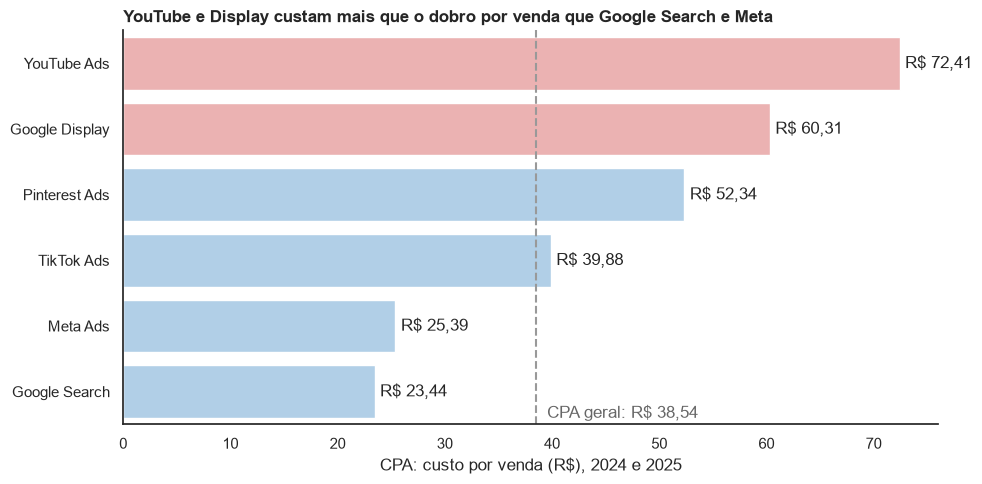

In [30]:
overall_cpa = channel_results['spend'].sum() / channel_results['conversions'].sum()
worst_channels = channel_results['channel_name'].head(2).tolist()
colors = {name: '#f4a9a8' if name in worst_channels else '#a8d0f0' for name in channel_results['channel_name']}

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=channel_results, x='cpa', y='channel_name', hue='channel_name', palette=colors, legend=False, ax=ax)

for container in ax.containers:
    labels = [f'R$ {value:.2f}'.replace('.', ',') for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=4)

ax.axvline(overall_cpa, color='#999999', linestyle='--')
ax.text(overall_cpa + 1, 5.4, f'CPA geral: R$ {overall_cpa:.2f}'.replace('.', ','), color='#666666')

ax.set_title('YouTube e Display custam mais que o dobro por venda que Google Search e Meta', loc='left', fontweight='bold')
ax.set_xlabel('CPA: custo por venda (R$), 2024 e 2025')
ax.set_ylabel('')
sns.despine()
plt.tight_layout()
plt.show()

**Observações da Pergunta 1:**

**Fatos:**
- Em 2024 e 2025 a Social Wave investiu **3,71 milhões** em mídia e conseguiu **96.203 vendas**, um CPA geral de **38,54** e um ROAS geral de **4,75**.
- A verba foi dividida quase igual: cada canal recebeu entre R$ 575 mil e R$ 638 mil. Mesmo com investimentos parecidos, os resultados são muito diferentes.
- **Google Search** (CPA 23,44, ROAS 8,97) e **Meta Ads** (CPA 25,39, ROAS 7,07) são os mais eficientes. Juntos trazem 51% das vendas com 33% da verba.
- **YouTube Ads** (CPA 72,41, ROAS 2,63) e **Google Display** (CPA 60,31, ROAS 2,81) são os menos eficientes. Cada venda custa mais que o dobro.

**Hipóteses (a confirmar nas próximas perguntas):**
- YouTube e Display podem estar **saturados**: recebem mais verba do que conseguem converter bem.
- Search e Meta podem ter **espaço para crescer**: se receberem mais verba, talvez continuem com CPA baixo.

**Recomendação inicial:** não cortar canais ainda. O CPA médio mostra o passado, mas não diz quanto cada canal renderia com **um real a mais**. Essa é a pergunta 4 (saturação), que vai guiar a redistribuição.

### 6.2 Pergunta 2: Em que etapa do funil cada canal perde mais gente?

In [31]:
query = '''
SELECT
    ch.channel_name,
    SUM(p.impressions) AS impressions,
    SUM(p.clicks) AS clicks,
    SUM(p.conversions) AS conversions,
    ROUND(100.0 * SUM(p.clicks) / SUM(p.impressions), 2) AS ctr,
    ROUND(100.0 * SUM(p.conversions) / SUM(p.clicks), 2) AS conversion_rate
FROM performance AS p
JOIN campaigns AS c ON p.campaign_id = c.campaign_id
JOIN channels AS ch ON c.channel_id = ch.channel_id
GROUP BY ch.channel_name
ORDER BY ctr DESC
'''
funnel = pd.read_sql(query, conn)
funnel

,channel_name,impressions,clicks,conversions,ctr,conversion_rate
0,Google Search,14408081,575732,24538,4.0,4.26
1,Meta Ads,31699607,380340,24967,1.2,6.56
2,TikTok Ads,53324885,479259,16000,0.9,3.34
3,Pinterest Ads,44721723,358363,12006,0.8,3.35
4,YouTube Ads,42012245,210658,8671,0.5,4.12
5,Google Display,75801844,302080,10021,0.4,3.32


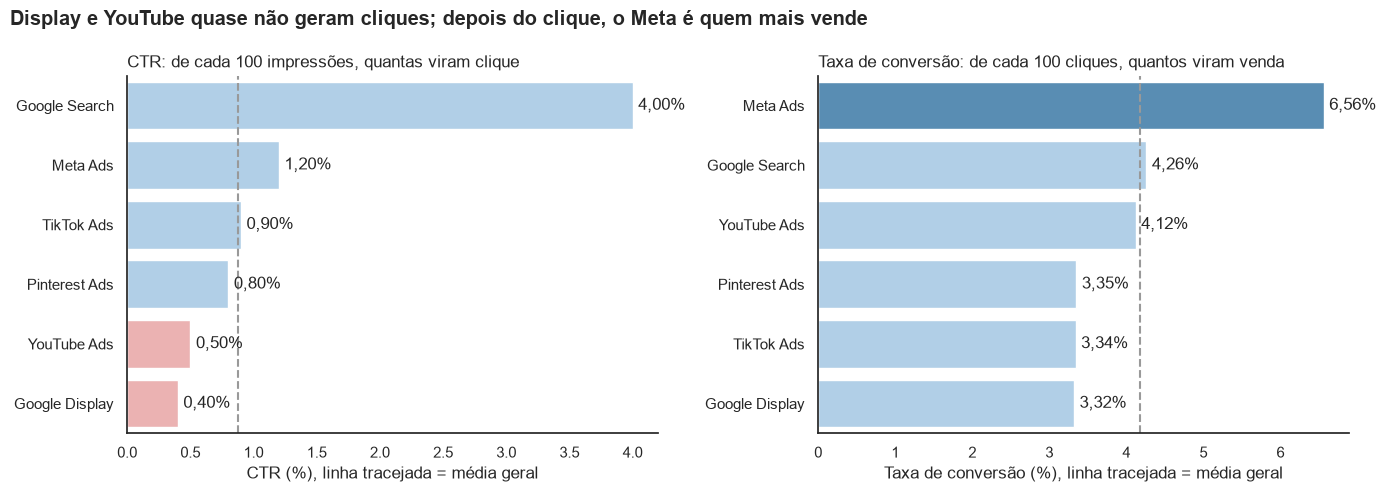

In [32]:
overall_ctr = 100 * funnel['clicks'].sum() / funnel['impressions'].sum()
overall_conversion = 100 * funnel['conversions'].sum() / funnel['clicks'].sum()

ctr_data = funnel.sort_values('ctr', ascending=False)
conversion_data = funnel.sort_values('conversion_rate', ascending=False)

ctr_colors = {name: '#f4a9a8' if name in ['Google Display', 'YouTube Ads'] else '#a8d0f0' for name in funnel['channel_name']}
conversion_colors = {name: '#4a90c2' if name == 'Meta Ads' else '#a8d0f0' for name in funnel['channel_name']}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=ctr_data, x='ctr', y='channel_name', hue='channel_name', palette=ctr_colors, legend=False, ax=axes[0])
axes[0].axvline(overall_ctr, color='#999999', linestyle='--')
axes[0].set_title('CTR: de cada 100 impressões, quantas viram clique', loc='left')
axes[0].set_xlabel('CTR (%), linha tracejada = média geral')

sns.barplot(data=conversion_data, x='conversion_rate', y='channel_name', hue='channel_name', palette=conversion_colors, legend=False, ax=axes[1])
axes[1].axvline(overall_conversion, color='#999999', linestyle='--')
axes[1].set_title('Taxa de conversão: de cada 100 cliques, quantos viram venda', loc='left')
axes[1].set_xlabel('Taxa de conversão (%), linha tracejada = média geral')

for ax in axes:
    for container in ax.containers:
        labels = [f'{value:.2f}%'.replace('.', ',') for value in container.datavalues]
        ax.bar_label(container, labels=labels, padding=4)
    ax.set_ylabel('')

fig.suptitle('Display e YouTube quase não geram cliques; depois do clique, o Meta é quem mais vende', x=0.01, ha='left', fontweight='bold')
sns.despine()
plt.tight_layout()
plt.show()

**Observações da Pergunta 2:**

**Fatos:**
- **Antes do clique:** Google Display (CTR de 0,40%) e YouTube Ads (0,50%) são os que menos geram clique. De cada 1.000 impressões, só 4 ou 5 pessoas clicam. O Google Search lidera com 4,00%, 10 vezes mais que o Display.
- **Depois do clique:** o Meta Ads converte **6,56%** dos cliques em venda, bem acima da média geral (4,17%). TikTok, Pinterest e Display ficam perto de 3,3%.
- O YouTube converte bem depois do clique (4,12%, perto da média). O problema dele está na primeira etapa: quase ninguém clica.

**Hipóteses:**
- O CTR baixo de Display e YouTube é parcialmente esperado: são canais de **divulgação da marca**, onde a pessoa não está procurando comprar. O Search, ao contrário, aparece pra quem já está buscando roupa.
- A conversão alta do Meta pode vir da **segmentação** (ele mostra o anúncio pra quem tem perfil de comprador) e do remarketing.
- TikTok e Pinterest atraem cliques, mas convertem pouco. O público pode estar só "olhando", ou a página de destino pode não estar ajudando.

**Recomendação:** para Display e YouTube, a questão não é a página do site, e sim quanto investir neles. Para TikTok e Pinterest, vale revisar a página de destino dos anúncios.

### 6.3 Pergunta 3: Como investimento, conversões e CPA mudaram ao longo de 2024 e 2025?

In [33]:
query = '''
SELECT
    SUBSTR(date, 1, 7) AS month,
    ROUND(SUM(spend), 2) AS spend,
    SUM(conversions) AS conversions,
    ROUND(SUM(spend) / SUM(conversions), 2) AS cpa
FROM performance
GROUP BY month
ORDER BY month
'''
monthly = pd.read_sql(query, conn)

monthly['year'] = monthly['month'].str[:4]
yearly = monthly.groupby('year')[['spend', 'conversions']].sum()
yearly['cpa'] = yearly['spend'] / yearly['conversions']
yearly

,spend,conversions,cpa
year,,,
2024,1614471.72,44227,36.504211
2025,2093284.56,51976,40.274060


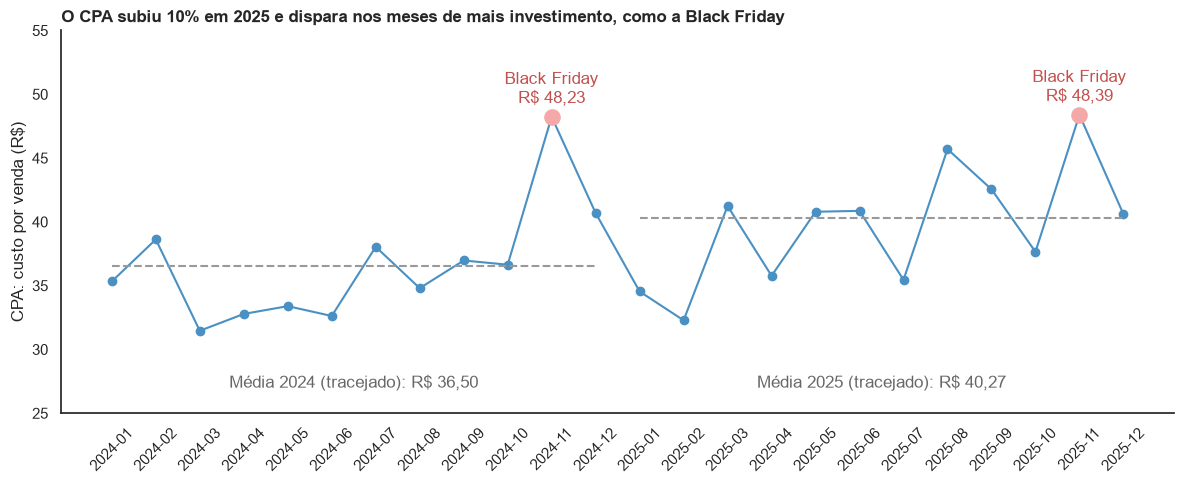

In [34]:
november = monthly[monthly['month'].str.endswith('-11')]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly['month'], monthly['cpa'], color='#4a90c2', marker='o')
ax.scatter(november['month'], november['cpa'], color='#f4a9a8', s=120, zorder=3)

for _, row in november.iterrows():
    ax.annotate(f'Black Friday\nR$ {row["cpa"]:.2f}'.replace('.', ','), (row['month'], row['cpa']),
                textcoords='offset points', xytext=(0, 10), ha='center', color='#c0504d')

for year, start, end in [('2024', 0, 11), ('2025', 12, 23)]:
    year_cpa = yearly.loc[year, 'cpa']
    ax.hlines(year_cpa, start, end, color='#999999', linestyle='--')
    ax.text((start + end) / 2, 27, f'Média {year} (tracejado): R$ {year_cpa:.2f}'.replace('.', ','),
            color='#666666', ha='center')

ax.set_title('O CPA subiu 10% em 2025 e dispara nos meses de mais investimento, como a Black Friday', loc='left', fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('CPA: custo por venda (R$)')
ax.set_ylim(25, 55)
ax.tick_params(axis='x', rotation=45)
sns.despine()
plt.tight_layout()
plt.show()

In [35]:
monthly['spend'].corr(monthly['cpa']).round(2)

np.float64(0.83)

**Observações da Pergunta 3:**

**Fatos:**
- De 2024 para 2025 o investimento subiu **29,7%** (de 1,61 mi para 2,09 mi), mas as vendas subiram só **17,5%** (de 44.227 para 51.976). Resultado: o CPA médio passou de **36,50 para 40,27 (+10,3%)**.
- Os meses de maior investimento são os de CPA mais alto. Em novembro de 2025 (Black Friday) foram investidos 279,6 mil, o maior valor do período, e o CPA chegou a **48,39**. Agosto de 2025, segundo maior investimento (227,6 mil), teve CPA de 45,70.
- A correlação entre investimento do mês e CPA é de **0,83**, uma relação forte: quanto mais se investe no mês, mais cara fica cada venda.

**Hipótese:** isso é o sinal clássico de **saturação**. Quando se coloca mais dinheiro nos mesmos canais, cada real extra traz menos vendas que o anterior. A Black Friday tem mais gente comprando, mas o aumento de verba foi maior que o aumento de vendas.

**Atenção:** correlação não é causa. Aqui ela só aponta o caminho. A próxima pergunta mede a saturação **canal por canal**, para saber onde o dinheiro extra rende e onde é desperdiçado.

### 6.4 Pergunta 4: A partir de que investimento cada canal começa a saturar?

Para cada canal, ajustamos uma **curva de saturação** que liga o investimento do dia às vendas do dia:

$$vendas = máximo \times (1 - e^{-investimento \, / \, velocidade})$$

- **máximo:** o teto de vendas por dia que o canal consegue entregar, mesmo com investimento infinito.
- **velocidade:** quão rápido o canal chega perto do teto. Quanto menor, mais cedo ele satura.

Com a curva, calculamos o **custo da próxima venda**: quanto seria preciso investir a mais, no nível atual de investimento, para conseguir uma venda extra. É diferente do CPA médio. O CPA médio olha o passado, e o custo da próxima venda olha o que o próximo real vai render.

In [38]:
query = '''
SELECT
    ch.channel_name,
    p.date,
    SUM(p.spend) AS spend,
    SUM(p.conversions) AS conversions
FROM performance AS p
JOIN campaigns AS c ON p.campaign_id = c.campaign_id
JOIN channels AS ch ON c.channel_id = ch.channel_id
GROUP BY ch.channel_name, p.date
'''
daily = pd.read_sql(query, conn)
daily.shape

(4379, 4)

In [39]:
def saturation(spend, max_conversions, speed):
    return max_conversions * (1 - np.exp(-spend / speed))


rows = []
for channel, data in daily.groupby('channel_name'):
    params, _ = curve_fit(saturation, data['spend'], data['conversions'],
                          p0=[data['conversions'].max(), data['spend'].mean()])
    current_spend = data.loc[data['date'] >= '2025-01-01', 'spend'].mean()
    rows.append({'channel_name': channel, 'max_conversions': params[0], 'speed': params[1], 'current_spend': current_spend})

curves = pd.DataFrame(rows)
curves['current_conversions'] = saturation(curves['current_spend'], curves['max_conversions'], curves['speed'])
curves['saturation'] = 100 * curves['current_conversions'] / curves['max_conversions']
curves['next_sale_cost'] = curves['speed'] / curves['max_conversions'] * np.exp(curves['current_spend'] / curves['speed'])
curves = curves.sort_values('next_sale_cost').round(2)
curves

,channel_name,max_conversions,speed,current_spend,current_conversions,saturation,next_sale_cost
2,Meta Ads,79.84,1471.20,954.94,38.12,47.75,35.27
1,Google Search,60.60,918.82,815.54,35.66,58.84,36.83
4,TikTok Ads,52.28,1519.02,1071.04,26.45,50.59,58.81
3,Pinterest Ads,28.21,910.09,1004.19,18.85,66.83,97.25
5,YouTube Ads,24.41,1183.74,1046.48,14.32,58.69,117.40
0,Google Display,19.24,579.58,863.38,14.90,77.46,133.64


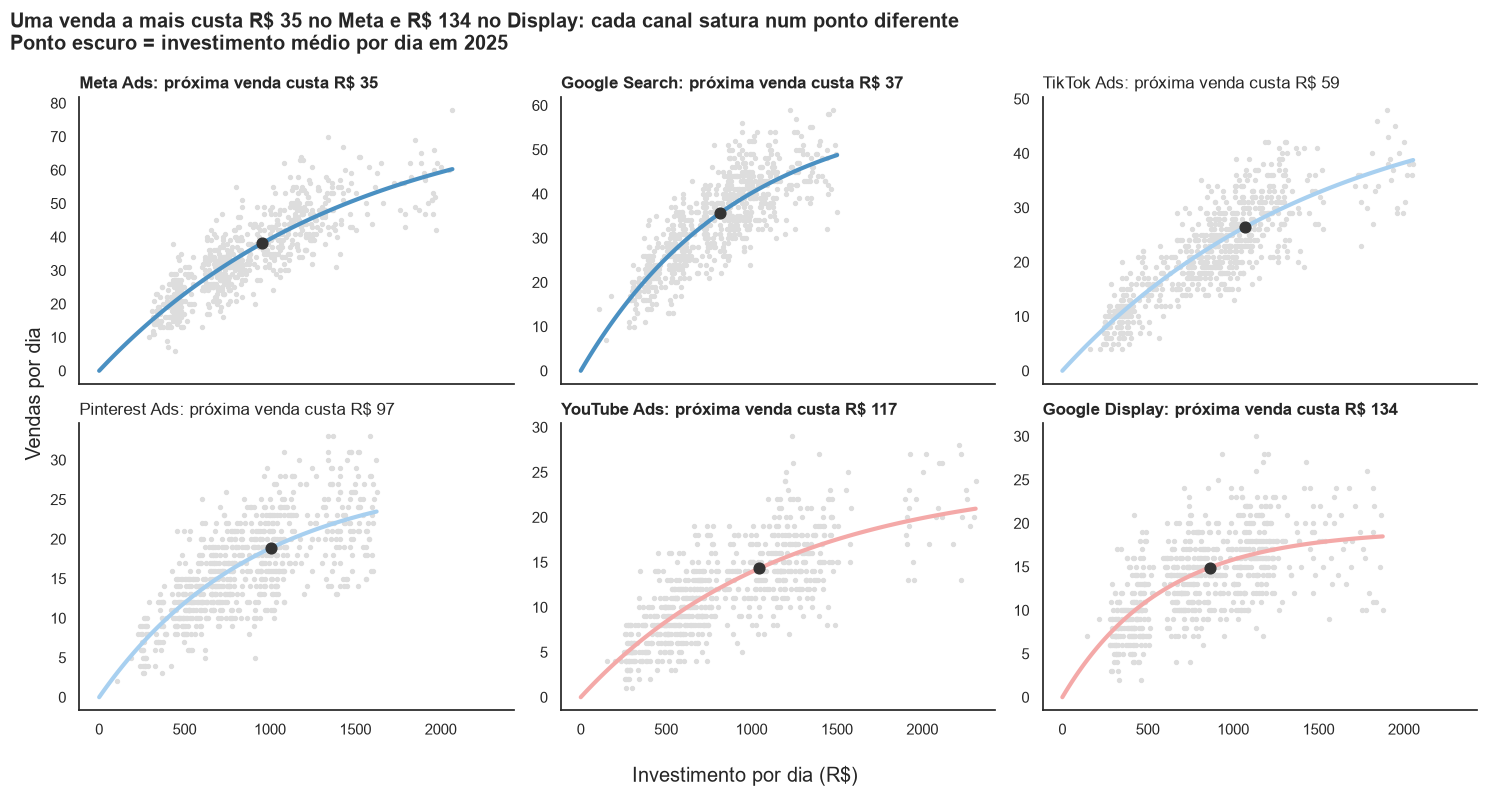

In [40]:
curve_colors = {'Meta Ads': '#4a90c2', 'Google Search': '#4a90c2', 'YouTube Ads': '#f4a9a8', 'Google Display': '#f4a9a8'}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)

for ax, (_, row) in zip(axes.flat, curves.iterrows()):
    data = daily[daily['channel_name'] == row['channel_name']]
    color = curve_colors.get(row['channel_name'], '#a8d0f0')
    spend_range = np.linspace(0, data['spend'].max(), 100)

    ax.scatter(data['spend'], data['conversions'], color='#dddddd', s=8)
    ax.plot(spend_range, saturation(spend_range, row['max_conversions'], row['speed']), color=color, linewidth=3)
    ax.scatter(row['current_spend'], row['current_conversions'], color='#333333', s=60, zorder=3)

    title = f'{row["channel_name"]}: próxima venda custa R$ {row["next_sale_cost"]:.0f}'
    ax.set_title(title, loc='left', fontweight='bold' if row['channel_name'] in curve_colors else 'normal')

fig.suptitle('Uma venda a mais custa R$ 35 no Meta e R$ 134 no Display: cada canal satura num ponto diferente\n'
             'Ponto escuro = investimento médio por dia em 2025',
             x=0.01, ha='left', fontweight='bold')
fig.supxlabel('Investimento por dia (R$)')
fig.supylabel('Vendas por dia')
sns.despine()
plt.tight_layout()
plt.show()

**Observações da Pergunta 4:**

**Fatos (pelo investimento médio por dia de 2025):**

| Canal | Investimento por dia | % do teto já atingido | Custo da próxima venda |
|---|---|---|---|
| Meta Ads | 955 | 48% | **35** |
| Google Search | 816 | 59% | **37** |
| TikTok Ads | 1.071 | 51% | 59 |
| Pinterest Ads | 1.004 | 67% | 97 |
| YouTube Ads | 1.046 | 59% | **117** |
| Google Display | 863 | 77% | **134** |

- **Meta e Search ainda têm espaço:** a próxima venda custa 35 a 37, abaixo do CPA médio de 2025 (40,27).
- **Display e YouTube estão saturados:** a próxima venda custa de 3 a 4 vezes mais. O Display já opera a 77% do seu teto.
- Os canais recebem verbas parecidas, mas estão em pontos muito diferentes da curva.

**O que isso significa:** cada 134 tirados do Display custam 1 venda lá, mas no Meta compram quase 4 vendas (134 ÷ 35). Mover dinheiro dos canais saturados para os que têm espaço aumenta as vendas **sem aumentar o orçamento**.

**Limitações:** a curva usa os dois anos juntos e não separa efeitos como a sazonalidade. Ela mostra a tendência de cada canal, não um valor exato. Por isso, a redistribuição deve ser feita aos poucos e acompanhada.

### 6.5 Pergunta 5: Como redistribuir o mesmo orçamento para ter o máximo de vendas?

Usando as curvas da pergunta 4, buscamos a divisão do orçamento que gera **o maior número de vendas**, seguindo duas regras:

- **Mesmo orçamento:** a soma do investimento por dia continua igual à média de 2025 (cerca de R\$ 5.756 por dia).
- **Mudanças com limite:** cada canal pode ficar entre **50% e 200%** do investimento atual. Isso evita mudanças bruscas e mantém cada canal perto da faixa de investimento que os dados já mostraram (fora dela, a curva é só uma extrapolação).

In [43]:
current_spend = curves['current_spend'].values
daily_budget = current_spend.sum()


def total_conversions(spend):
    return saturation(spend, curves['max_conversions'].values, curves['speed'].values).sum()


def negative_conversions(spend):
    return -total_conversions(spend)


def same_budget(spend):
    return spend.sum() - daily_budget


limits = [(0.5 * spend, 2 * spend) for spend in current_spend]
result = minimize(negative_conversions, x0=current_spend, bounds=limits,
                  constraints={'type': 'eq', 'fun': same_budget})
result.success

True

In [44]:
budget_plan = curves[['channel_name', 'current_spend']].copy()
budget_plan['optimized_spend'] = result.x
budget_plan['change'] = budget_plan['optimized_spend'] - budget_plan['current_spend']
budget_plan['change_pct'] = 100 * budget_plan['change'] / budget_plan['current_spend']
budget_plan['current_conversions'] = saturation(budget_plan['current_spend'], curves['max_conversions'], curves['speed'])
budget_plan['optimized_conversions'] = saturation(budget_plan['optimized_spend'], curves['max_conversions'], curves['speed'])
budget_plan = budget_plan.sort_values('change', ascending=False).round(2)
budget_plan

,channel_name,current_spend,optimized_spend,change,change_pct,current_conversions,optimized_conversions
2,Meta Ads,954.94,1783.86,828.92,86.80,38.12,56.09
1,Google Search,815.54,1295.28,479.74,58.83,35.65,45.80
4,TikTok Ads,1071.04,1141.63,70.59,6.59,26.45,27.62
3,Pinterest Ads,1004.19,579.86,-424.33,-42.26,18.85,13.29
0,Google Display,863.38,431.69,-431.69,-50.00,14.90,10.10
5,YouTube Ads,1046.48,523.24,-523.24,-50.00,14.33,8.72


In [45]:
current_total = total_conversions(current_spend)
optimized_total = total_conversions(result.x)

summary = pd.DataFrame({
    'scenario': ['Atual', 'Otimizado'],
    'daily_budget': [daily_budget, result.x.sum()],
    'daily_conversions': [current_total, optimized_total],
    'cpa': [daily_budget / current_total, result.x.sum() / optimized_total],
    'yearly_conversions': [current_total * 365, optimized_total * 365],
}).round(2)
summary

,scenario,daily_budget,daily_conversions,cpa,yearly_conversions
0,Atual,5755.57,148.31,38.81,54131.84
1,Otimizado,5755.57,161.63,35.61,58996.37


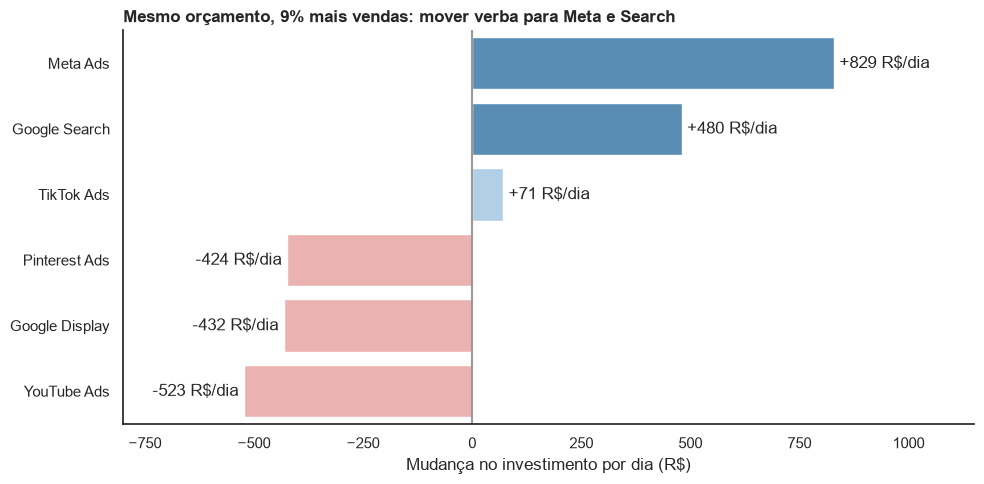

In [46]:
def change_color(change):
    if change > 100:
        return '#4a90c2'
    if change < -100:
        return '#f4a9a8'
    return '#a8d0f0'


colors = {row['channel_name']: change_color(row['change']) for _, row in budget_plan.iterrows()}

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=budget_plan, x='change', y='channel_name', hue='channel_name', palette=colors, legend=False, ax=ax)

for container in ax.containers:
    labels = [f'{value:+,.0f}'.replace(',', '.') + ' R$/dia' for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=4)

ax.axvline(0, color='#999999')
ax.set_xlim(-800, 1150)
ax.set_title('Mesmo orçamento, 9% mais vendas: mover verba para Meta e Search', loc='left', fontweight='bold')
ax.set_xlabel('Mudança no investimento por dia (R$)')
ax.set_ylabel('')
sns.despine()
plt.tight_layout()
plt.show()

**Observações da Pergunta 5:**

**Fatos (estimativas pelas curvas de saturação):**

| Canal | Hoje (por dia) | Proposta (por dia) | Mudança |
|---|---|---|---|
| Meta Ads | 955 | 1.784 | **+87%** |
| Google Search | 816 | 1.295 | **+59%** |
| TikTok Ads | 1.071 | 1.142 | +7% |
| Pinterest Ads | 1.004 | 580 | −42% |
| Google Display | 863 | 432 | **−50%** |
| YouTube Ads | 1.046 | 523 | **−50%** |

- Com o **mesmo orçamento** (5.756 por dia, cerca de 2,1 milhões por ano), as vendas estimadas sobem de **148 para 162 por dia (+9,0%)**.
- O CPA estimado cai de **38,81 para 35,61 (−8,2%)**.
- Em um ano, são cerca de **4.865 vendas a mais** sem gastar nenhum real extra.
- Display e YouTube pararam no limite mínimo (−50%). Ou seja, o modelo cortaria ainda mais se fosse permitido.

**Recomendação:**
1. Fazer a mudança **em etapas** (por exemplo, metade em janeiro e o resto em fevereiro), acompanhando o CPA de cada canal semana a semana.
2. **Não zerar** Display e YouTube: eles ajudam a divulgar a marca, um efeito que o modelo de última venda não mede.
3. Refazer as curvas a cada trimestre com os dados novos, porque a saturação muda com a concorrência e a época do ano.

**Limitação:** os números são estimativas do modelo, não uma garantia. O ganho real só se confirma depois de aplicar a mudança e medir.

### 6.6 Pergunta 6: O criativo novo converte mais que o atual de verdade, ou foi sorte?

Para saber se a diferença entre os grupos é real, usamos o **teste qui-quadrado**. Ele parte de uma suposição chamada **hipótese nula**: os dois criativos vendem igual, e qualquer diferença é sorte do sorteio.

O teste devolve o **p-valor**, que é a chance de ver uma diferença tão grande quanto a nossa **se os criativos fossem iguais**.

- **p-valor menor que 0,05 (5%):** é muito improvável que seja sorte. A diferença é real.
- **p-valor maior ou igual a 0,05:** não dá para descartar a sorte. Não temos evidência de diferença.

A métrica principal é a **taxa de conversão por pessoa**: das pessoas que viram o anúncio, quantas compraram.

In [48]:
query = '''
SELECT
    "group",
    COUNT(*) AS people,
    SUM(clicked) AS clicks,
    SUM(converted) AS conversions,
    ROUND(100.0 * SUM(clicked) / COUNT(*), 2) AS ctr,
    ROUND(100.0 * SUM(converted) / COUNT(*), 2) AS conversion_rate
FROM ab_test
GROUP BY "group"
'''
ab_results = pd.read_sql(query, conn)
ab_results

,group,people,clicks,conversions,ctr,conversion_rate
0,A,20059,2246,439,11.20,2.19
1,B,19821,2383,510,12.02,2.57


In [49]:
table = pd.crosstab(ab_test_clean['group'], ab_test_clean['converted'])
chi2, p_value, _, _ = chi2_contingency(table)

rate_a = ab_test_clean.loc[ab_test_clean['group'] == 'A', 'converted'].mean()
rate_b = ab_test_clean.loc[ab_test_clean['group'] == 'B', 'converted'].mean()
lift = 100 * (rate_b - rate_a) / rate_a

print(f'Taxa de conversão A: {100 * rate_a:.2f}%')
print(f'Taxa de conversão B: {100 * rate_b:.2f}%')
print(f'Aumento do B sobre o A: {lift:.1f}%')
print(f'p-valor: {p_value:.4f}')
table

Taxa de conversão A: 2.19%
Taxa de conversão B: 2.57%
Aumento do B sobre o A: 17.6%
p-valor: 0.0129


converted,0,1
group,,
A,19620,439
B,19311,510


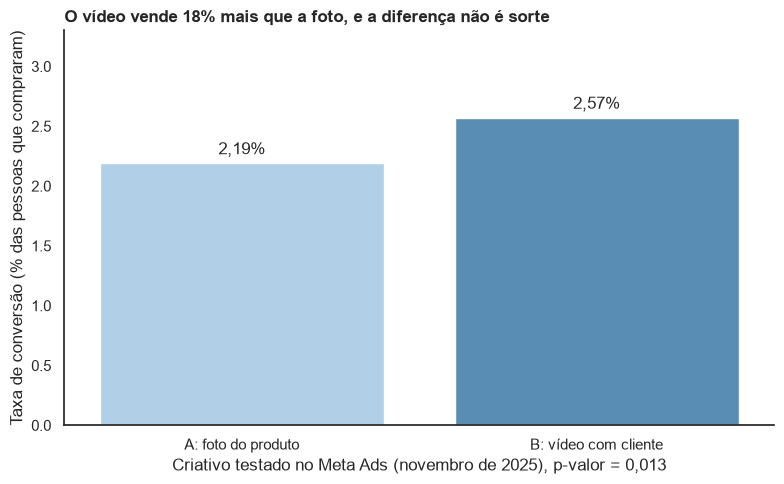

In [50]:
colors = {'A': '#a8d0f0', 'B': '#4a90c2'}
ab_results['label'] = ab_results['group'].map({'A': 'A: foto do produto', 'B': 'B: vídeo com cliente'})

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=ab_results, x='label', y='conversion_rate', hue='group', palette=colors, legend=False, ax=ax)

for container in ax.containers:
    labels = [f'{value:.2f}%'.replace('.', ',') for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=4, fontsize=12)

ax.set_title(f'O vídeo vende {lift:.0f}% mais que a foto, e a diferença não é sorte', loc='left', fontweight='bold')
ax.set_xlabel(f'Criativo testado no Meta Ads (novembro de 2025), p-valor = {p_value:.3f}'.replace('.', ','))
ax.set_ylabel('Taxa de conversão (% das pessoas que compraram)')
ax.set_ylim(0, 3.3)
sns.despine()
plt.tight_layout()
plt.show()

**Observações da Pergunta 6:**

**Fatos:**
- **Grupo A (foto):** 20.059 pessoas, 439 compras, taxa de conversão de **2,19%**.
- **Grupo B (vídeo):** 19.821 pessoas, 510 compras, taxa de conversão de **2,57%**.
- O vídeo vendeu **17,6% a mais** que a foto. Ele também gerou mais cliques (CTR de 12,02% contra 11,20%).
- O **p-valor é 0,013**, abaixo de 0,05. A chance de uma diferença desse tamanho aparecer só por sorte é de cerca de 1%. **A diferença é real.**

**Recomendação:**
- Trocar o criativo atual pelo **vídeo com cliente** em todas as campanhas do Meta Ads.
- O ganho se soma ao da pergunta 5: o Meta é justamente o canal que mais vai receber verba na redistribuição, então um criativo melhor ali rende ainda mais.
- Testar o mesmo formato de vídeo no TikTok e no Pinterest, que geram clique mas convertem pouco (pergunta 2), com um novo teste A/B em cada canal.

**Limitação:** o teste durou 4 semanas de novembro, mês de Black Friday. Vale acompanhar a taxa de conversão nos meses seguintes para confirmar que o efeito se mantém fora da época de promoções.

## 7. Conclusões e Recomendações

### 7.1 Respostas às perguntas de negócio

| # | Pergunta | Resposta |
|---|---|---|
| 1 | Quanto investimos e quanto retornou em cada canal? | 3,71 mi investidos, 96.203 vendas, CPA geral de 38,54. Google Search (23,44) e Meta (25,39) são os mais eficientes. YouTube (72,41) e Display (60,31) custam mais que o dobro por venda. |
| 2 | Em que etapa do funil cada canal perde mais gente? | Display e YouTube perdem **antes do clique** (CTR de 0,4% e 0,5%). TikTok e Pinterest perdem **depois do clique** (conversão de 3,3%). O Meta é o que mais converte depois do clique (6,6%). |
| 3 | Como os resultados mudaram no tempo? | Em 2025 o investimento subiu 29,7% e as vendas só 17,5%. O CPA foi de 36,50 para 40,27 (+10,3%) e chega a 48 nas Black Fridays. Investimento do mês e CPA têm correlação de 0,83. |
| 4 | Quando cada canal começa a saturar? | No nível atual, a próxima venda custa 35 no Meta e 37 no Search, contra 117 no YouTube e 134 no Display. O Display já opera a 77% do seu teto. |
| 5 | Como redistribuir o mesmo orçamento? | Mais verba para Meta (+87%) e Search (+59%), menos para YouTube e Display (−50%) e Pinterest (−42%). Estimativa: **+9,0% de vendas** (cerca de 4.865 por ano) e **CPA 8,2% menor**, sem aumentar o orçamento. |
| 6 | O criativo novo converte mais? | Sim. O vídeo converteu 2,57% contra 2,19% da foto (**+17,6%**), com p-valor de 0,013. A diferença é real. |

### 7.2 Principais descobertas

- **O problema não é quanto se investe, é onde.** Os 6 canais receberam verbas parecidas, mas estão em pontos muito diferentes da curva de saturação.
- **CPA médio engana na hora de decidir.** Ele mostra o custo das vendas que já aconteceram. O que decide para onde vai o próximo real é o **custo da próxima venda**.
- **A alta do CPA em 2025 é sinal de saturação:** mais dinheiro foi colocado nos mesmos canais sem olhar quanto cada um ainda rendia.
- **Canal e criativo se somam:** o Meta tem espaço para crescer e agora tem um criativo comprovadamente melhor.

### 7.3 Plano de ação

| Prioridade | Ação | Por quê | Impacto esperado |
|---|---|---|---|
| **Alta** | Redistribuir o orçamento em 2 etapas (metade em janeiro, o resto em fevereiro de 2026) | Meta e Search têm espaço; Display, YouTube e Pinterest estão saturados | +9% de vendas e CPA 8% menor, com o mesmo orçamento |
| **Alta** | Trocar o criativo do Meta Ads pelo vídeo com cliente | Teste A/B mostrou +17,6% de conversão (p = 0,013) | Mais vendas justamente no canal que vai receber mais verba |
| **Média** | Acompanhar o CPA de cada canal toda semana e refazer as curvas a cada trimestre | A saturação muda com a concorrência e a época do ano | Corrigir a rota rápido se algum canal não responder como previsto |
| **Média** | Revisar a página de destino dos anúncios de TikTok e Pinterest | Geram clique, mas convertem só 3,3% | Mais vendas sem gastar mais com anúncio |
| **Baixa** | Testar o vídeo no TikTok e no Pinterest com novos testes A/B | O formato funcionou no Meta | Confirmar se o ganho se repete em outros canais |
| **Baixa** | Planejar a Black Friday olhando a saturação | Nas Black Fridays o CPA chegou a R\$ 48 | Colocar o aumento de verba só nos canais com espaço |

### 7.4 Limitações

- **Dados fictícios:** as bases foram geradas para este estudo de caso. Os números ilustram o método, não um mercado real.
- **Curvas sem sazonalidade:** a curva de cada canal usa os dois anos juntos e não separa o efeito da época do ano.
- **Efeito de marca não medido:** Display e YouTube ajudam a divulgar a marca, um efeito que não aparece na venda direta. Por isso a recomendação é reduzir, não zerar.
- **Estimativas, não garantias:** o ganho da redistribuição é uma estimativa do modelo e só se confirma depois de aplicar e medir.
- **Teste A/B em novembro:** o teste aconteceu num mês de Black Friday. Vale confirmar o efeito nos meses seguintes.

### 7.5 Próximos passos

- Medir o resultado real da redistribuição comparando o CPA antes e depois, canal por canal.
- Ajustar curvas por trimestre para capturar a sazonalidade.
- Trocar "vendas" por **lucro** como objetivo da otimização, considerando o ticket médio e a margem de cada canal.